<a href="https://colab.research.google.com/github/kattaNagasainikhila-wq/AI-Iris-Classification/blob/main/spam_ham_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install nltk scikit-learn pandas numpy matplotlib seaborn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import re

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving sms+spam+collection.zip to sms+spam+collection.zip


In [ ]:
import zipfile
import os

zip_name = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_name, 'r') as zip_ref:
    zip_ref.extractall('/content/dataset')

print("ZIP file extracted successfully!")

ZIP file extracted successfully!


In [ ]:
for root, dirs, filenames in os.walk('/content/dataset'):
    for filename in filenames:
        print(os.path.join(root, filename))

/content/dataset/readme
/content/dataset/SMSSpamCollection


In [ ]:

import pandas as pd

# Load SMS Spam Collection dataset
file_path = "/content/dataset/SMSSpamCollection"

df = pd.read_csv(
    file_path,
    sep='\t',
    header=None,
    names=['label', 'message']
)

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [ ]:

# Display first 10 messages
df.head(10)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


In [ ]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Shape: (5572, 2)

Column Names:
Index(['label', 'message'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Missing Values:
label      0
message    0
dtype: int64


In [ ]:

print(df['label'].value_counts())

print("\nPercentage Distribution:")
print(df['label'].value_counts(normalize=True) * 100)


label
ham     4825
spam     747
Name: count, dtype: int64

Percentage Distribution:
label
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


In [ ]:

# Check duplicate records
print("Duplicate messages:", df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)


Duplicate messages: 403
Shape after removing duplicates: (5169, 2)


In [ ]:

print(df.isnull().sum())


label      0
message    0
dtype: int64


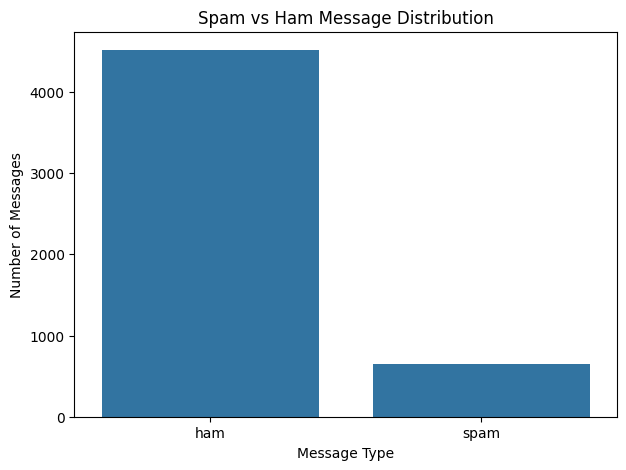

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7,5))

sns.countplot(data=df, x='label')

plt.title("Spam vs Ham Message Distribution")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")

plt.show()


In [ ]:

# Calculate message length
df['message_length'] = df['message'].apply(len)

print(df.groupby('label')['message_length'].describe())


        count        mean        std   min    25%    50%    75%    max
label                                                                 
ham    4516.0   70.905890  56.715046   2.0   34.0   53.0   91.0  910.0
spam    653.0  137.704441  29.821348  13.0  132.0  148.0  157.0  223.0


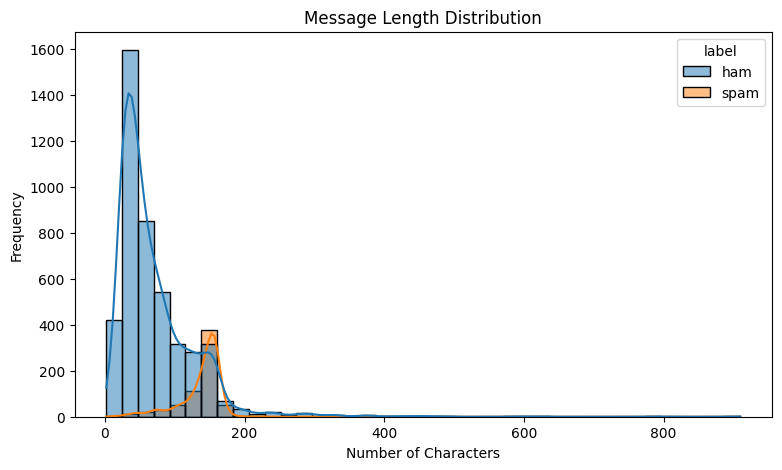

In [ ]:

plt.figure(figsize=(9,5))

sns.histplot(
    data=df,
    x='message_length',
    hue='label',
    bins=40,
    kde=True
)

plt.title("Message Length Distribution")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")

plt.show()


In [ ]:

import re
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')

print("Libraries imported successfully!")


Libraries imported successfully!


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:

stop_words = set(stopwords.words('english'))

# Preserve negation words because they can change meaning
stop_words = stop_words - {'no', 'not', 'nor'}

print("Total stopwords:", len(stop_words))


Total stopwords: 195


In [ ]:

def clean_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove punctuation and special characters
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)

    # Remove stopwords
    words = text.split()
    words = [word for word in words if word not in stop_words]

    # Join words
    text = ' '.join(words)

    return text


In [ ]:

df['clean_message'] = df['message'].apply(clean_text)

# Display original and cleaned messages
df[['message', 'clean_message']].head(10)


,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry 2 wkly comp win fa cup final tkts 2...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think goes usf lives around though
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darling 3 weeks no word back id li...
6,Even my brother is not like to speak with me. ...,even brother not like speak treat like aids pa...
7,As per your request 'Melle Melle (Oru Minnamin...,per request melle melle oru minnaminunginte nu...
8,WINNER!! As a valued network customer you have...,winner valued network customer selected receiv...
9,Had your mobile 11 months or more? U R entitle...,mobile 11 months u r entitled update latest co...


In [ ]:

import re
import nltk

from nltk.corpus import stopwords

nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

# Preserve negation words
stop_words = stop_words - {'no', 'not', 'nor'}

def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)

    words = text.split()
    words = [word for word in words if word not in stop_words]

    return ' '.join(words)

# Apply preprocessing
df['clean_message'] = df['message'].apply(clean_text)

# Display results
df[['message', 'clean_message']].head(10)


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry 2 wkly comp win fa cup final tkts 2...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think goes usf lives around though
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darling 3 weeks no word back id li...
6,Even my brother is not like to speak with me. ...,even brother not like speak treat like aids pa...
7,As per your request 'Melle Melle (Oru Minnamin...,per request melle melle oru minnaminunginte nu...
8,WINNER!! As a valued network customer you have...,winner valued network customer selected receiv...
9,Had your mobile 11 months or more? U R entitle...,mobile 11 months u r entitled update latest co...


In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF
tfidf = TfidfVectorizer(max_features=5000)

# Convert messages into numerical features
X = tfidf.fit_transform(df['clean_message'])

print("TF-IDF transformation completed!")
print("Feature matrix shape:", X.shape)


TF-IDF transformation completed!
Feature matrix shape: (5169, 5000)


In [ ]:

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y = le.fit_transform(df['label'])

print("Label encoding completed!")
print("Classes:", le.classes_)
print("Encoded labels:", y[:10])


Label encoding completed!
Classes: ['ham' 'spam']
Encoded labels: [0 0 1 0 0 1 0 0 1 1]


In [ ]:

from sklearn.model_selection import train_test_split

# Input and output
X_text = df['clean_message']
y = df['label'].map({'ham': 0, 'spam': 1})

# Split dataset
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train_text))
print("Testing samples:", len(X_test_text))


Training samples: 4135
Testing samples: 1034


In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

# Learn vocabulary only from training messages
X_train = tfidf.fit_transform(X_train_text)

# Transform testing messages using the same vocabulary
X_test = tfidf.transform(X_test_text)

print("Training matrix:", X_train.shape)
print("Testing matrix:", X_test.shape)


Training matrix: (4135, 5000)
Testing matrix: (1034, 5000)


In [ ]:

from sklearn.naive_bayes import MultinomialNB

# Initialize model
model = MultinomialNB()

# Train model
model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [ ]:

# Predict testing data
y_pred = model.predict(X_test)

print("Actual labels:")
print(y_test.values[:10])

print("\nPredicted labels:")
print(y_pred[:10])


Actual labels:
[0 0 0 0 0 0 0 0 0 0]

Predicted labels:
[0 0 0 0 0 0 0 0 0 0]


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("MODEL PERFORMANCE")
print("-------------------------")

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1 Score:", round(f1 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Ham', 'Spam']
))


MODEL PERFORMANCE
-------------------------
Accuracy: 96.81 %
Precision: 100.0 %
Recall: 74.81 %
F1 Score: 85.59 %

Classification Report:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       903
        Spam       1.00      0.75      0.86       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.92      1034
weighted avg       0.97      0.97      0.97      1034



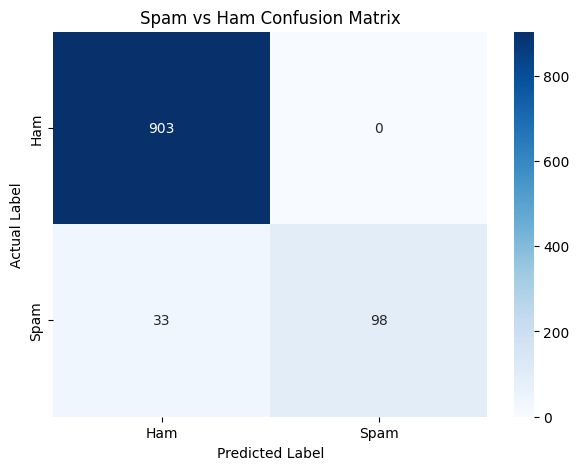

In [ ]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.title("Spam vs Ham Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()


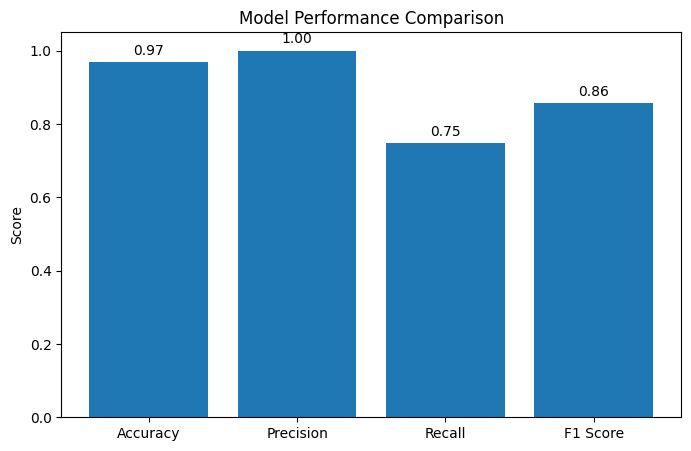

In [ ]:

metrics = {
    'Accuracy': accuracy,
    'Precision': precision,
    'Recall': recall,
    'F1 Score': f1
}

plt.figure(figsize=(8,5))

plt.bar(metrics.keys(), metrics.values())

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)

for i, value in enumerate(metrics.values()):
    plt.text(i, value + 0.02, f'{value:.2f}', ha='center')

plt.show()


In [ ]:

def predict_message(message):

    # Clean the input message
    cleaned = clean_text(message)

    # Convert into TF-IDF features
    vector = tfidf.transform([cleaned])

    # Predict
    prediction = model.predict(vector)[0]

    if prediction == 1:
        print("Result: SPAM MESSAGE")
    else:
        print("Result: HAM MESSAGE")

# Test messages
predict_message("Congratulations! You won a free lottery prize. Claim now!")
predict_message("Hey buddy, how are you? Shall we meet tomorrow?")
predict_message("URGENT! Your account has won 50000 rupees. Click here now!")


Result: SPAM MESSAGE
Result: HAM MESSAGE
Result: SPAM MESSAGE


In [ ]:

my_message = input("Enter an SMS message: ")

predict_message(my_message)


Enter an SMS message: hii you won alottery
Result: HAM MESSAGE


In [ ]:

from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression
lr_model = LogisticRegression(max_iter=1000)

# Train model
lr_model.fit(X_train, y_train)

# Predictions
lr_pred = lr_model.predict(X_test)

# Calculate performance
lr_accuracy = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred)
lr_recall = recall_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)

print("LOGISTIC REGRESSION PERFORMANCE")
print("--------------------------------")

print("Accuracy:", round(lr_accuracy * 100, 2), "%")
print("Precision:", round(lr_precision * 100, 2), "%")
print("Recall:", round(lr_recall * 100, 2), "%")
print("F1 Score:", round(lr_f1 * 100, 2), "%")


LOGISTIC REGRESSION PERFORMANCE
--------------------------------
Accuracy: 95.55 %
Precision: 94.74 %
Recall: 68.7 %
F1 Score: 79.65 %


      Metric  Naive Bayes  Logistic Regression
0   Accuracy     0.968085             0.955513
1  Precision     1.000000             0.947368
2     Recall     0.748092             0.687023
3   F1 Score     0.855895             0.796460


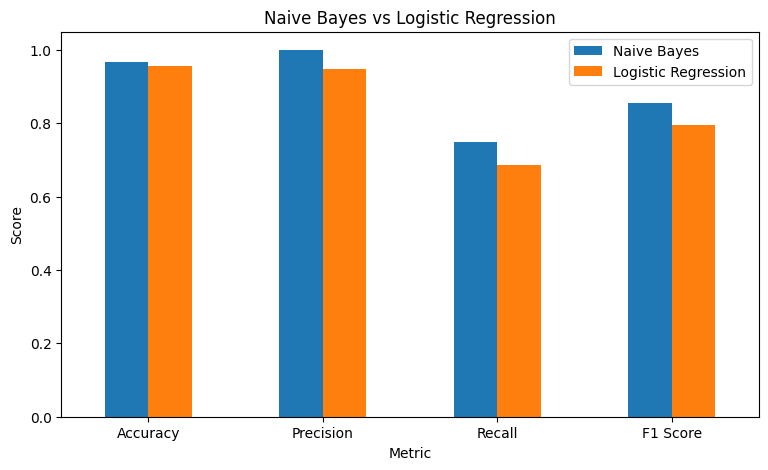

In [ ]:

comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Naive Bayes': [accuracy, precision, recall, f1],
    'Logistic Regression': [
        lr_accuracy,
        lr_precision,
        lr_recall,
        lr_f1
    ]
})

print(comparison)

comparison.set_index('Metric').plot(
    kind='bar',
    figsize=(9,5)
)

plt.title("Naive Bayes vs Logistic Regression")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.show()


In [ ]:

import joblib

# Save Naive Bayes model
joblib.dump(model, 'spam_ham_model.pkl')

# Save TF-IDF vectorizer
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

print("Model and vectorizer saved successfully!")


Model and vectorizer saved successfully!


In [ ]:

from google.colab import files

files.download('spam_ham_model.pkl')
files.download('tfidf_vectorizer.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>